### Import Libraries & Setup

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

### Loading Data & Data Cleaning

In [13]:
file_path = r"C:\Users\amylo\OneDrive\Desktop\sleep project\Sleep_health_and_lifestyle_dataset.csv"
df = pd.read_csv(file_path)

if 'Blood Pressure' in df.columns:
    df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True)
    df['Systolic_BP'] = pd.to_numeric(df['Systolic_BP'])
    df['Diastolic_BP'] = pd.to_numeric(df['Diastolic_BP'])
    df = df.drop(columns=['Blood Pressure'])

if 'BMI Category' in df.columns:
    df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})

display(df.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,NaN,126,83
1,2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,NaN,125,80
2,3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,NaN,125,80
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


### Exploratory Data Analysis (EDA) & Visualizations

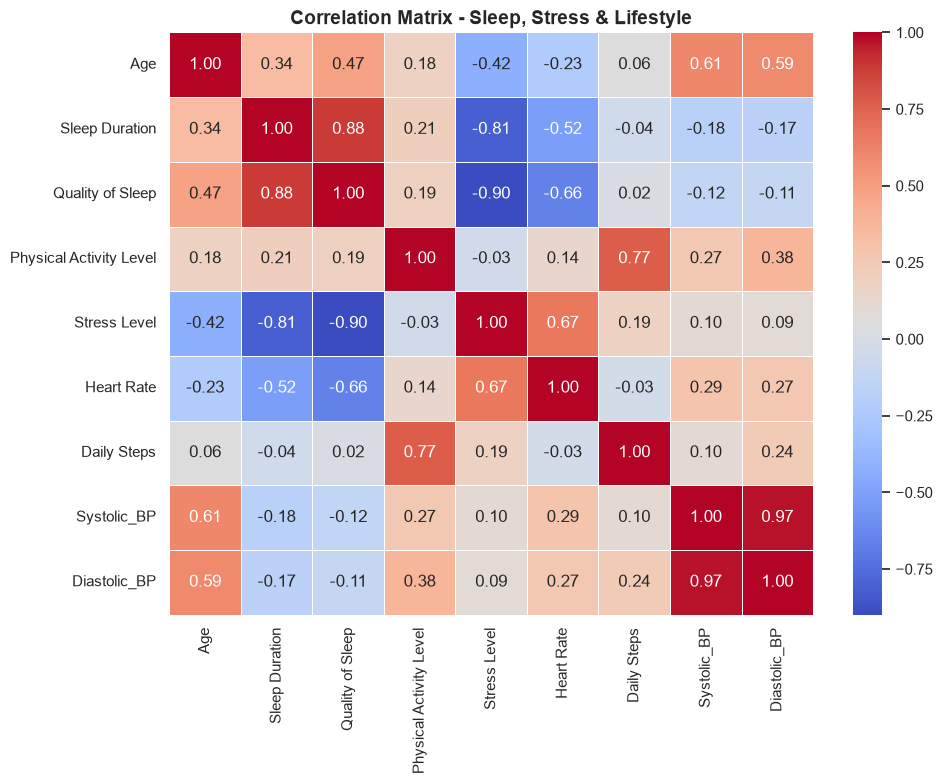

In [14]:

if 'Person ID' in df.columns:
    df_corr = df.drop(columns=['Person ID'])
else:
    df_corr = df

numeric_df = df_corr.select_dtypes(include=['number'])

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix - Sleep, Stress & Lifestyle', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Sleep Duration vs. Sleep Disorder
This box plot compares sleep duration distributions across different sleep disorder categories, highlighting how duration varies for healthy individuals versus those with insomnia or sleep apnea.

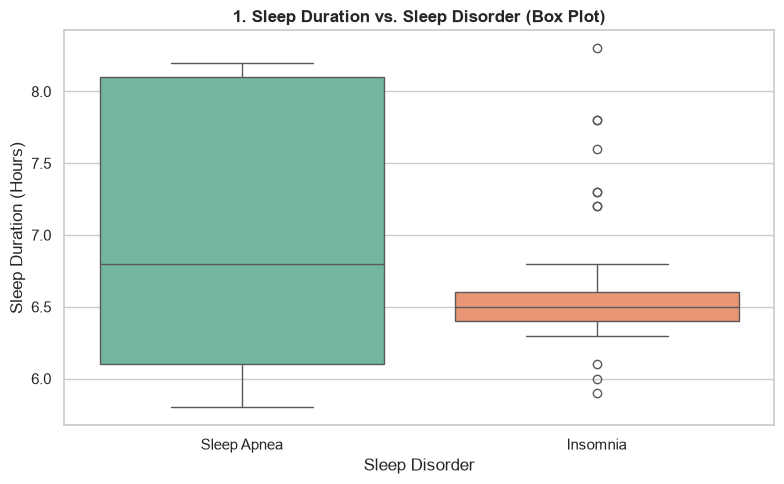

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Sleep Disorder', y='Sleep Duration', data=df, hue='Sleep Disorder', palette='Set2', legend=False)
plt.title('1. Sleep Duration vs. Sleep Disorder (Box Plot)', fontsize=12, fontweight='bold')
plt.xlabel('Sleep Disorder')
plt.ylabel('Sleep Duration (Hours)')
plt.tight_layout()
plt.show()

#### Sleep Duration vs. Stress Level
A scatter plot combined with a regression trendline, illustrating the negative correlation between how long people sleep and their reported stress levels.

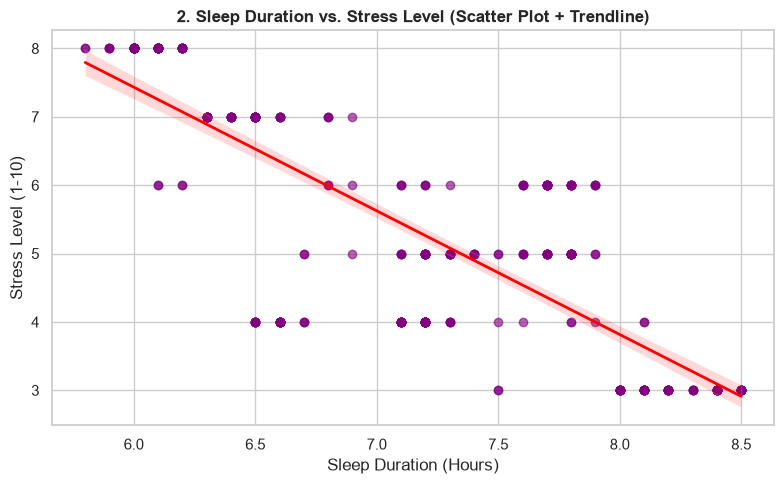

In [16]:
plt.figure(figsize=(8, 5))
sns.regplot(x='Sleep Duration', y='Stress Level', data=df, 
            scatter_kws={'alpha': 0.6, 'color': 'purple'}, line_kws={'color': 'red', 'linewidth': 2})
plt.title('2. Sleep Duration vs. Stress Level (Scatter Plot + Trendline)', fontsize=12, fontweight='bold')
plt.xlabel('Sleep Duration (Hours)')
plt.ylabel('Stress Level (1-10)')
plt.tight_layout()
plt.show()

#### Average Stress Level by Occupation
A horizontal bar chart ranking different professions by their average reported stress levels, showing which occupations experience the highest pressure.

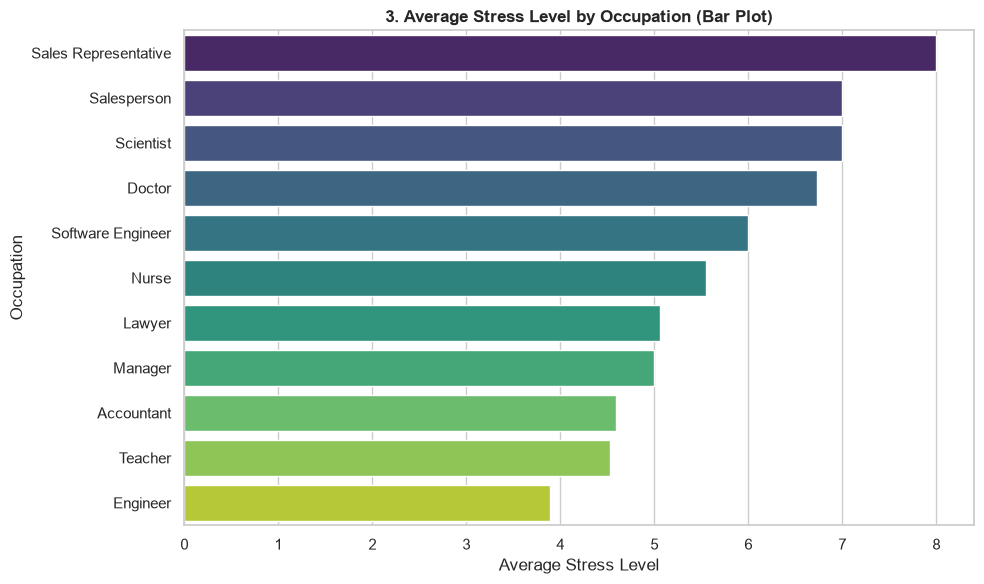

In [17]:
occupation_stress = df.groupby('Occupation')['Stress Level'].mean().reset_index().sort_values(by='Stress Level', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Stress Level', y='Occupation', data=occupation_stress, 
            hue='Occupation', palette='viridis', legend=False)
plt.title('3. Average Stress Level by Occupation (Bar Plot)', fontsize=12, fontweight='bold')
plt.xlabel('Average Stress Level')
plt.ylabel('Occupation')
plt.tight_layout()
plt.show()

#### Quality of Sleep by BMI Category
A violin plot displaying the data density and distribution of sleep quality scores across various BMI categories, complete with quartile markers.

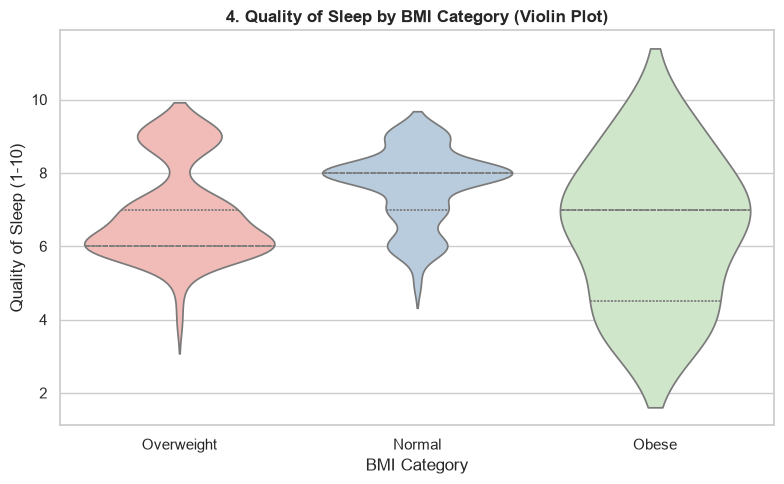

In [18]:
plt.figure(figsize=(8, 5))
sns.violinplot(x='BMI Category', y='Quality of Sleep', data=df, 
               hue='BMI Category', palette='Pastel1', inner='quartile', legend=False)
plt.title('4. Quality of Sleep by BMI Category (Violin Plot)', fontsize=12, fontweight='bold')
plt.xlabel('BMI Category')
plt.ylabel('Quality of Sleep (1-10)')
plt.tight_layout()
plt.show()

#### Sleep Duration vs. Physical Activity Level
A scatter plot with a regression line exploring the relationship between daily physical activity (in minutes) and total sleep duration.

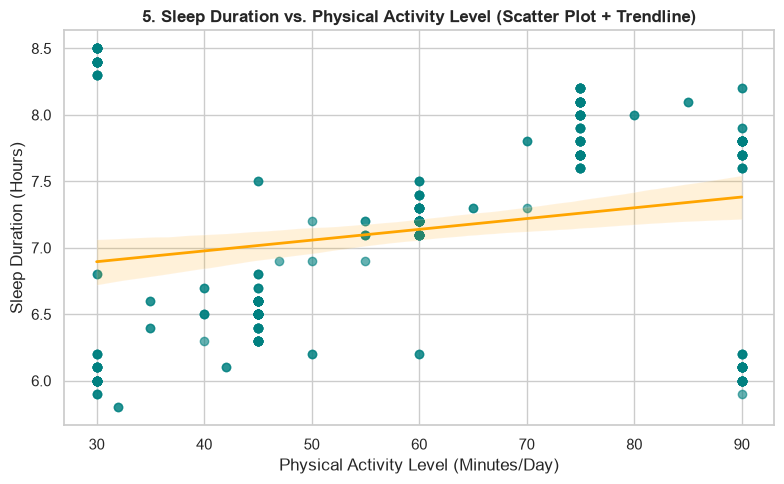

In [19]:
plt.figure(figsize=(8, 5))
sns.regplot(x='Physical Activity Level', y='Sleep Duration', data=df, 
            scatter_kws={'alpha': 0.6, 'color': 'teal'}, line_kws={'color': 'orange', 'linewidth': 2})
plt.title('5. Sleep Duration vs. Physical Activity Level (Scatter Plot + Trendline)', fontsize=12, fontweight='bold')
plt.xlabel('Physical Activity Level (Minutes/Day)')
plt.ylabel('Sleep Duration (Hours)')
plt.tight_layout()
plt.show()

### Machine Learning & Predictive Modeling

In [10]:

X = df.drop(columns=['Sleep Disorder'])
y = df['Sleep Disorder']

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape (Training data):", X_train.shape)
print("X_test shape (Test data):", X_test.shape)

X_train shape (Training data): (299, 22)
X_test shape (Test data): (75, 22)


#### Train Random Forest Model & Evaluate Performance

In [11]:

model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 88.00%

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.72      0.81      0.76        16
        None       0.95      0.98      0.97        43
 Sleep Apnea       0.85      0.69      0.76        16

    accuracy                           0.88        75
   macro avg       0.84      0.83      0.83        75
weighted avg       0.88      0.88      0.88        75



##  Project Summary & Research Question

**Project Objective:** To investigate whether lifestyle metrics and physiological data can predict sleep disorders.

* **Key Insights from Exploratory Data Analysis (EDA):**
  * A clear statistical relationship was found between sleep duration, stress levels, BMI, and the presence of sleep disorders such as Insomnia and Sleep Apnea.
  * Healthy individuals tend to sleep significantly more hours on average and exhibit lower stress levels compared to those with sleep disorders.

* **Machine Learning Model Results:**
  * We trained a **Random Forest** classifier which achieved an impressive overall accuracy of **88%** in predicting sleep disorders on unseen test data.
  * The classification report demonstrates that the model excels at identifying healthy individuals (95% precision) and provides a strong foundation for decision-support systems in healthcare for early risk detection.

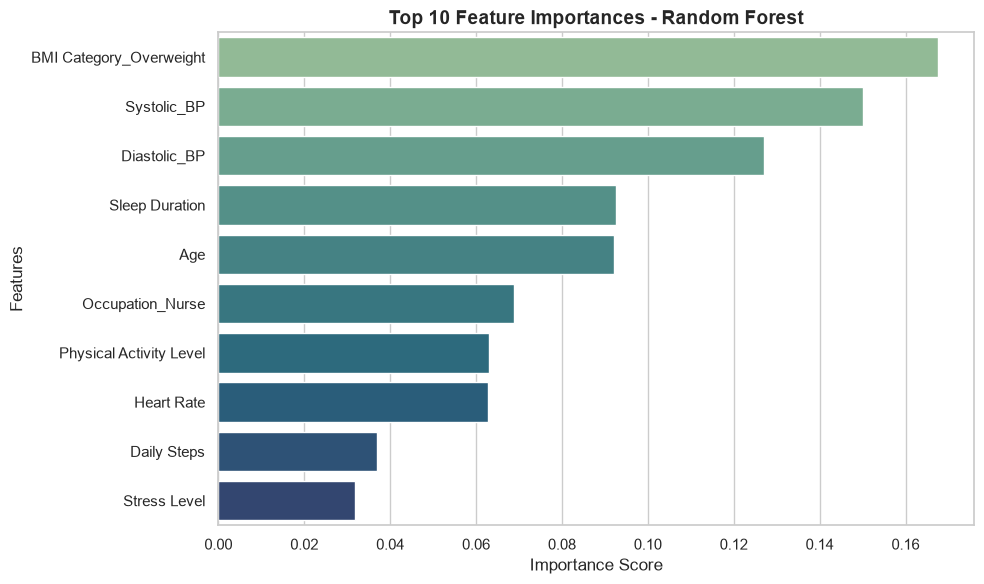

In [20]:
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances.head(10), hue='Feature', palette='crest', legend=False)
plt.title('Top 10 Feature Importances - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()